# Amazon Chronos BASE for Sideslip State Estimation

## Competition: Sensing the Drift - V2 with LARGER MODEL

### Latest Kaggle Results (small model):
| Submission | Score | Status |
|------------|-------|--------|
| `finetuned_opt` | **0.543** | ✓ BEST |
| `weighted` (30%ZS+70%FT) | 0.643 | Worse |
| `ensemble` (50/50) | 0.743 | Much worse |
| `zero_shot_opt` | FAILED | MAE 0.295 > threshold |

### Key Insight:
- **Zero-shot is failing** the many-shot region and dragging down ensembles
- **Pure fine-tuned is best** - focus entirely on fine-tuning optimization
- **Upgrade to chronos-t5-base (200M params)** for richer embeddings

### V2 Optimization Strategy:
1. **Upgrade Model**: `chronos-t5-base` (200M params vs 46M)
2. **Skip Zero-Shot**: Don't waste time, it fails threshold
3. **Focus on Fine-Tuning**: 
   - WeightedL1 Loss with tuned threshold/slope
   - Two-stage training
   - Deeper MLP with residual connections

   - More training epochs### Expected Output: 49,328 predictions


In [14]:
# =============================================================================
# SETUP & IMPORTS - OPTIMIZED VERSION
# =============================================================================
import sys
import os
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("/home/mdesouky/workspace/mait_g2_drift_challenge")
sys.path.insert(0, str(PROJECT_ROOT))

# Import project utilities
from utils.data_loading import load_data, load_test_data, feature_names
from utils.custom_datasets import sequential_dataset
from utils.reproducibility_utils import seed_everything

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Chronos
from chronos import ChronosPipeline

# Sklearn for zero-shot experiments
from sklearn.linear_model import Ridge, LinearRegression, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.svm import SVR

# Reproducibility
SEED = 42
seed_everything(SEED)

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

# =============================================================================
# CONFIGURATION - OPTIMIZED
# =============================================================================
TRAIN_PATH = PROJECT_ROOT / "datasets_challenge" / "train"
TEST_PATH = PROJECT_ROOT / "datasets_challenge" / "test"

SEQ_LENGTH = 20
BATCH_SIZE = 256
TARGET = 'sideSlip'
COLUMNS_TO_DROP = ["sideSlip", "vyCG", "time", "longitude", "latitude"]
EXPECTED_ROWS = 49328

# Training config - OPTIMIZED
TRAIN_RATIO = 0.8  # Can try 0.9 or 0.95 for more training data

print(f"\n{'='*60}")
print(f"OPTIMIZED Configuration:")
print(f"  Sequence length: {SEQ_LENGTH}")
print(f"  Features: {len(feature_names)}")
print(f"  Expected predictions: {EXPECTED_ROWS}")
print(f"  Training ratio: {TRAIN_RATIO}")
print(f"{'='*60}")

Device: cuda

OPTIMIZED Configuration:
  Sequence length: 20
  Features: 22
  Expected predictions: 49328
  Training ratio: 0.8


## Step 1: Load Training Data Using Project Pipeline

In [15]:
# =====================================
# CELL 4: Load Training Data
# =====================================
"""
Load training data using project's data_loading utility.
CRITICAL: Use threshold=True to filter low speed samples (vxCG < 3.0)
This ensures the pipeline is consistent with working examples.
"""

train_loader, val_loader, pipeline = load_data(
    train_path=str(TRAIN_PATH),
    train_ratio=0.8,
    columns_to_standardize=feature_names,
    columns_to_drop=COLUMNS_TO_DROP,
    sequence_length=SEQ_LENGTH,
    target=TARGET,
    threshold=True,           # CRITICAL: Filter low speed samples
    threshold_value=3.0,      # vxCG > 3.0
    threshold_column="vxCG",
    batchsize=BATCH_SIZE,
    scaling=True,
    seed=SEED,
    shuffle=True
)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")

# Check batch shapes
sample_x, sample_y = next(iter(train_loader))
N_FEATURES = sample_x.shape[2]
print(f"\nBatch shapes:")
print(f"  Input (X): {sample_x.shape}")   # [batch, seq_len, features]
print(f"  Target (y): {sample_y.shape}")  # [batch]
print(f"  N_FEATURES: {N_FEATURES}")

/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_001.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_002.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_003.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_004.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_005.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_006.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_007.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_008.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_009.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_010.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/tr

## Step 2: Load Amazon Chronos Model

Chronos is a time-series foundation model. We'll extract embeddings from sensor sequences and use them for sideslip regression.

In [16]:
# Load Chronos model - UPGRADED to BASE (200M params)
chronos_pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-base",  # 200M params - 4x larger!
    device_map=device,
    torch_dtype=torch.float32,
)

print(f"Chronos model loaded on {device}")
print(f"Model type: chronos-t5-base (200M parameters) - UPGRADED!")

Chronos model loaded on cuda
Model type: chronos-t5-base (200M parameters) - UPGRADED!


## Step 3: Chronos State Estimator Model

We create a model that:
1. Uses Chronos encoder to extract embeddings from each sensor channel
2. Concatenates embeddings from all sensors
3. Passes through a trainable regression head to predict sideslip

In [17]:
class ChronosStateEstimator(nn.Module):
    """
    State estimator using Chronos embeddings.
    - Extracts embeddings from key sensor channels using frozen Chronos encoder
    - Concatenates with raw sensor features
    - Trainable regression head predicts sideslip
    """
    def __init__(self, chronos_pipeline, n_features, hidden_dim=128, n_key_sensors=5):
        super().__init__()
        self.chronos = chronos_pipeline
        self.n_features = n_features
        self.n_key_sensors = n_key_sensors
        
        # Chronos embedding dimension (T5-small has 512-dim embeddings)
        self.chronos_embed_dim = 512
        
        # Key sensor indices for Chronos (most relevant for sideslip)
        # yawRate, ayCG, handwheelAngle, rollRate, vxCG
        self.key_sensor_names = ['yawRate', 'ayCG', 'handwheelAngle', 'rollRate', 'vxCG']
        self.key_sensor_indices = [feature_names.index(name) for name in self.key_sensor_names if name in feature_names]
        self.n_key_sensors = len(self.key_sensor_indices)
        
        # Input: chronos embeddings (n_key_sensors * embed_dim) + raw features (n_features)
        total_input_dim = self.n_key_sensors * self.chronos_embed_dim + n_features
        
        # Regression head (trainable)
        self.regression_head = nn.Sequential(
            nn.Linear(total_input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim // 2, 1)
        )
        
        print(f"ChronosStateEstimator initialized:")
        print(f"  Key sensors: {self.key_sensor_names[:self.n_key_sensors]}")
        print(f"  Chronos embed dim: {self.chronos_embed_dim}")
        print(f"  Total input dim: {total_input_dim}")
        
    @torch.no_grad()
    def extract_chronos_embeddings(self, x):
        """Extract Chronos embeddings for key sensor channels."""
        # x: [batch, seq_len, features]
        batch_size = x.shape[0]
        embeddings = []
        
        for sensor_idx in self.key_sensor_indices:
            # Get sensor time series [batch, seq_len]
            sensor_data = x[:, :, sensor_idx]
            
            # Get Chronos embeddings using the model's encoder
            # We need to access the underlying T5 encoder
            tokenizer_output = self.chronos.tokenizer.context_input_transform(sensor_data)
            token_ids = tokenizer_output.to(x.device)
            
            # Get encoder embeddings
            with torch.no_grad():
                encoder_output = self.chronos.model.model.encoder(
                    input_ids=token_ids,
                    return_dict=True
                )
                # Mean pool over sequence dimension
                embed = encoder_output.last_hidden_state.mean(dim=1)  # [batch, embed_dim]
                embeddings.append(embed)
        
        # Concatenate all sensor embeddings
        return torch.cat(embeddings, dim=-1)  # [batch, n_sensors * embed_dim]
    
    def forward(self, x):
        # x: [batch, seq_len, features]
        
        # Extract Chronos embeddings (frozen)
        chronos_embed = self.extract_chronos_embeddings(x)
        
        # Get last timestep raw features
        raw_features = x[:, -1, :]  # [batch, features]
        
        # Concatenate
        combined = torch.cat([chronos_embed, raw_features], dim=-1)
        
        # Regression head
        output = self.regression_head(combined)
        return output.squeeze(-1)


class SimpleLSTM(nn.Module):
    """Simple LSTM baseline for comparison."""
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_dim, hidden_dim, num_layers,
            batch_first=True, bidirectional=True, dropout=dropout
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out[:, -1, :])
        return out.squeeze(-1)

print("Model classes defined.")

Model classes defined.


## Step 4: Zero-Shot Chronos Inference

Test Chronos embeddings with a simple linear regression head (no fine-tuning of Chronos).

In [18]:
# Zero-shot: Extract Chronos embeddings and train only a linear head
from sklearn.linear_model import Ridge

def extract_chronos_features_batch(chronos_pipeline, x_batch, key_sensor_indices):
    """Extract Chronos embeddings for a batch of sequences."""
    batch_size = x_batch.shape[0]
    all_embeddings = []
    
    for sensor_idx in key_sensor_indices:
        # Move sensor data to CPU for tokenization (Chronos tokenizer expects CPU tensors)
        sensor_data = x_batch[:, :, sensor_idx].cpu()  # [batch, seq_len]
        
        # Get Chronos embeddings
        with torch.no_grad():
            # Tokenize on CPU
            tokenizer_output = chronos_pipeline.tokenizer.context_input_transform(sensor_data)
            # context_input_transform returns (token_ids, attention_mask, scale)
            token_ids = tokenizer_output[0].to(device)
            attention_mask = tokenizer_output[1].to(device)
            
            # Get encoder embeddings
            encoder_output = chronos_pipeline.model.model.encoder(
                input_ids=token_ids,
                attention_mask=attention_mask,
                return_dict=True
            )
            # Mean pool over sequence (considering attention mask)
            hidden_states = encoder_output.last_hidden_state  # [batch, seq, 512]
            # Mask and mean pool
            mask_expanded = attention_mask.unsqueeze(-1).float()
            sum_hidden = (hidden_states * mask_expanded).sum(dim=1)
            count = mask_expanded.sum(dim=1).clamp(min=1)
            embed = sum_hidden / count  # [batch, 512]
            all_embeddings.append(embed.cpu().numpy())
    
    # Concatenate sensor embeddings
    return np.concatenate(all_embeddings, axis=1)  # [batch, n_sensors * 512]

# Key sensors for sideslip estimation
key_sensor_names = ['yawRate', 'ayCG', 'handwheelAngle', 'rollRate', 'vxCG']
key_sensor_indices = [feature_names.index(name) for name in key_sensor_names if name in feature_names]
print(f"Key sensors: {key_sensor_names}")
print(f"Indices: {key_sensor_indices}")

# Extract features from training data
print("\nExtracting Chronos embeddings from training data...")
X_chronos_train = []
X_raw_train = []
y_train_list = []

for batch_x, batch_y in tqdm(train_loader, desc="Train batches"):
    batch_x = batch_x.to(device)
    
    # Chronos embeddings
    chronos_feat = extract_chronos_features_batch(chronos_pipeline, batch_x, key_sensor_indices)
    X_chronos_train.append(chronos_feat)
    
    # Raw features (last timestep)
    X_raw_train.append(batch_x[:, -1, :].cpu().numpy())
    y_train_list.append(batch_y.numpy())

X_chronos_train = np.vstack(X_chronos_train)
X_raw_train = np.vstack(X_raw_train)
y_train = np.concatenate(y_train_list)

# Combine Chronos + raw features
X_train_combined = np.hstack([X_chronos_train, X_raw_train])

print(f"\nTraining data shapes:")
print(f"  Chronos features: {X_chronos_train.shape}")
print(f"  Raw features: {X_raw_train.shape}")
print(f"  Combined: {X_train_combined.shape}")
print(f"  Targets: {y_train.shape}")

Key sensors: ['yawRate', 'ayCG', 'handwheelAngle', 'rollRate', 'vxCG']
Indices: [6, 5, 0, 7, 3]

Extracting Chronos embeddings from training data...


Train batches: 100%|██████████| 429/429 [04:53<00:00,  1.46it/s]



Training data shapes:
  Chronos features: (109665, 3840)
  Raw features: (109665, 22)
  Combined: (109665, 3862)
  Targets: (109665,)


In [19]:
# =============================================================================
# EXTRACT VALIDATION FEATURES & ZERO-SHOT EXPERIMENTS
# =============================================================================

print("Extracting Chronos embeddings from validation data...")
X_chronos_val = []
X_raw_val = []
y_val_list = []

for batch_x, batch_y in tqdm(val_loader, desc="Val batches"):
    batch_x = batch_x.to(device)
    
    chronos_feat = extract_chronos_features_batch(chronos_pipeline, batch_x, key_sensor_indices)
    X_chronos_val.append(chronos_feat)
    X_raw_val.append(batch_x[:, -1, :].cpu().numpy())
    y_val_list.append(batch_y.numpy())

X_chronos_val = np.vstack(X_chronos_val)
X_raw_val = np.vstack(X_raw_val)
y_val = np.concatenate(y_val_list)
X_val_combined = np.hstack([X_chronos_val, X_raw_val])

print(f"Validation shapes: {X_val_combined.shape}, {y_val.shape}")

# =============================================================================
# ZERO-SHOT EXPERIMENTS - Try multiple models
# =============================================================================
print("\n" + "="*60)
print("ZERO-SHOT MODEL COMPARISON")
print("="*60)

zero_shot_results = {}

# 1. Ridge with different alphas
for alpha in [0.01, 0.1, 1.0, 10.0]:
    model = Ridge(alpha=alpha)
    model.fit(X_train_combined, y_train)
    y_pred = model.predict(X_val_combined)
    mae = np.mean(np.abs(y_pred - y_val))
    zero_shot_results[f'Ridge(alpha={alpha})'] = (mae, model)
    print(f"  Ridge(alpha={alpha}): MAE = {mae:.4f}")

# 2. Linear Regression (no regularization)
model = LinearRegression()
model.fit(X_train_combined, y_train)
y_pred = model.predict(X_val_combined)
mae = np.mean(np.abs(y_pred - y_val))
zero_shot_results['LinearRegression'] = (mae, model)
print(f"  LinearRegression: MAE = {mae:.4f}")

# 3. ElasticNet
model = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=1000)
model.fit(X_train_combined, y_train)
y_pred = model.predict(X_val_combined)
mae = np.mean(np.abs(y_pred - y_val))
zero_shot_results['ElasticNet'] = (mae, model)
print(f"  ElasticNet: MAE = {mae:.4f}")

# Find best zero-shot model
best_zs_name = min(zero_shot_results.keys(), key=lambda k: zero_shot_results[k][0])
zero_shot_mae, best_zs_model = zero_shot_results[best_zs_name]

print(f"\n✓ Best Zero-Shot: {best_zs_name} with MAE = {zero_shot_mae:.4f}")
print(f"  RNN Baseline: 0.217")

Extracting Chronos embeddings from validation data...


Val batches: 100%|██████████| 108/108 [01:10<00:00,  1.52it/s]


Validation shapes: (27415, 3862), (27415,)

ZERO-SHOT MODEL COMPARISON
  Ridge(alpha=0.01): MAE = 0.3044
  Ridge(alpha=0.1): MAE = 0.3081
  Ridge(alpha=1.0): MAE = 0.3189
  Ridge(alpha=10.0): MAE = 0.3375
  LinearRegression: MAE = 0.3742
  ElasticNet: MAE = 0.4299

✓ Best Zero-Shot: Ridge(alpha=0.01) with MAE = 0.3044
  RNN Baseline: 0.217


## Step 5: Fine-Tune Regression Head - OPTIMIZED

### Key Optimizations:
1. **WeightedL1 Loss**: From winning RNN - weights extreme values more heavily
2. **Two-stage training**: Stage 1 with L1, Stage 2 with WeightedL1
3. **More epochs**: 30 (S1) + 40 (S2) = 70 total
4. **Better architecture**: Wider network with skip connections

In [20]:
# =============================================================================
# OPTIMIZED MLP & LOSS FUNCTIONS
# =============================================================================

# WeightedL1 Loss - From winning RNN (task16)
class WeightedL1Loss(nn.Module):
    """
    Weighted L1 loss that gives higher weight to extreme (rare) values.
    This is CRITICAL for Kaggle metric which penalizes errors on extreme sideslip.
    
    weight = 1.0 + slope * max(0, |target| - threshold)
    """
    def __init__(self, threshold=2.0, slope=1.0):
        super().__init__()
        self.threshold = threshold
        self.slope = slope
        
    def forward(self, pred, target):
        # Calculate weights based on target magnitude
        weights = 1.0 + self.slope * torch.clamp(torch.abs(target) - self.threshold, min=0)
        # Weighted L1 loss
        return (torch.abs(pred - target) * weights).mean()


# Optimized MLP with residual connections
class OptimizedMLPHead(nn.Module):
    """
    Optimized MLP with:
    - Wider layers (512 -> 256 -> 128 -> 1)
    - Residual connection for first block
    - BatchNorm instead of LayerNorm for better training
    """
    def __init__(self, input_dim, hidden_dim=512):
        super().__init__()
        
        # First block with residual
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc1_proj = nn.Linear(input_dim, hidden_dim)  # Projection for residual
        
        # Second block
        self.fc2 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.bn2 = nn.BatchNorm1d(hidden_dim // 2)
        
        # Third block
        self.fc3 = nn.Linear(hidden_dim // 2, hidden_dim // 4)
        self.bn3 = nn.BatchNorm1d(hidden_dim // 4)
        
        # Output
        self.out = nn.Linear(hidden_dim // 4, 1)
        
        self.act = nn.GELU()
        self.dropout = nn.Dropout(0.2)
        
    def forward(self, x):
        # First block with residual
        identity = self.fc1_proj(x)
        out = self.act(self.bn1(self.fc1(x)))
        out = self.dropout(out) + identity  # Residual
        
        # Second block
        out = self.act(self.bn2(self.fc2(out)))
        out = self.dropout(out)
        
        # Third block
        out = self.act(self.bn3(self.fc3(out)))
        
        # Output
        return self.out(out).squeeze(-1)


# Create dataloaders
train_tensor_dataset = TensorDataset(
    torch.tensor(X_train_combined, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)
val_tensor_dataset = TensorDataset(
    torch.tensor(X_val_combined, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

train_feat_loader = DataLoader(train_tensor_dataset, batch_size=512, shuffle=True)
val_feat_loader = DataLoader(val_tensor_dataset, batch_size=512, shuffle=False)

# Initialize optimized model
input_dim = X_train_combined.shape[1]
mlp_model = OptimizedMLPHead(input_dim, hidden_dim=512).to(device)

print(f"Optimized MLP Input dim: {input_dim}")
print(f"Total parameters: {sum(p.numel() for p in mlp_model.parameters()):,}")
print(f"\nUsing WeightedL1Loss (threshold=2.0, slope=1.0)")

Optimized MLP Input dim: 3862
Total parameters: 4,121,857

Using WeightedL1Loss (threshold=2.0, slope=1.0)


In [21]:
# =============================================================================
# TWO-STAGE TRAINING (from winning RNN)
# =============================================================================
"""
Stage 1: Train with standard L1 loss (30 epochs, lr=0.0003)
Stage 2: Fine-tune with WeightedL1 loss (40 epochs, lr=0.00005)
"""

history = {'train_loss': [], 'val_mae': [], 'stage': []}
best_val_mae = float('inf')

# ===== STAGE 1: L1 Loss =====
print("="*60)
print("STAGE 1: Training with L1 Loss (30 epochs)")
print("="*60)

criterion_l1 = nn.L1Loss()
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.0003)

S1_EPOCHS = 30
for epoch in range(S1_EPOCHS):
    # Train
    mlp_model.train()
    train_loss = 0
    for batch_x, batch_y in train_feat_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        pred = mlp_model(batch_x)
        loss = criterion_l1(pred, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_feat_loader)
    
    # Validate
    mlp_model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for batch_x, batch_y in val_feat_loader:
            batch_x = batch_x.to(device)
            pred = mlp_model(batch_x)
            val_preds.extend(pred.cpu().numpy())
            val_targets.extend(batch_y.numpy())
    
    val_mae = np.mean(np.abs(np.array(val_preds) - np.array(val_targets)))
    history['train_loss'].append(train_loss)
    history['val_mae'].append(val_mae)
    history['stage'].append(1)
    
    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_state_s1 = mlp_model.state_dict().copy()
    
    if (epoch + 1) % 10 == 0:
        print(f"S1 Epoch {epoch+1}/{S1_EPOCHS} | Train: {train_loss:.4f} | Val MAE: {val_mae:.4f}")

print(f"\nStage 1 Best Val MAE: {best_val_mae:.4f}")

# Load best S1 model for Stage 2
mlp_model.load_state_dict(best_state_s1)

# ===== STAGE 2: WeightedL1 Loss =====
print("\n" + "="*60)
print("STAGE 2: Fine-tuning with WeightedL1 Loss (40 epochs)")
print("="*60)

criterion_weighted = WeightedL1Loss(threshold=2.0, slope=1.0)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.00005)

S2_EPOCHS = 40
best_val_mae_s2 = float('inf')

for epoch in range(S2_EPOCHS):
    # Train
    mlp_model.train()
    train_loss = 0
    for batch_x, batch_y in train_feat_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        pred = mlp_model(batch_x)
        loss = criterion_weighted(pred, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_feat_loader)
    
    # Validate with standard MAE
    mlp_model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for batch_x, batch_y in val_feat_loader:
            batch_x = batch_x.to(device)
            pred = mlp_model(batch_x)
            val_preds.extend(pred.cpu().numpy())
            val_targets.extend(batch_y.numpy())
    
    val_mae = np.mean(np.abs(np.array(val_preds) - np.array(val_targets)))
    history['train_loss'].append(train_loss)
    history['val_mae'].append(val_mae)
    history['stage'].append(2)
    
    if val_mae < best_val_mae_s2:
        best_val_mae_s2 = val_mae
        torch.save(mlp_model.state_dict(), 'chronos_optimized_best.pth')
    
    if (epoch + 1) % 10 == 0:
        print(f"S2 Epoch {epoch+1}/{S2_EPOCHS} | Train: {train_loss:.4f} | Val MAE: {val_mae:.4f}")

# Load best model
mlp_model.load_state_dict(torch.load('chronos_optimized_best.pth'))

print(f"\n{'='*60}")
print(f"OPTIMIZED FINE-TUNING RESULTS:")
print(f"  Stage 1 Best MAE:    {best_val_mae:.4f}")
print(f"  Stage 2 Best MAE:    {best_val_mae_s2:.4f}")
print(f"  Zero-Shot MAE:       {zero_shot_mae:.4f}")
print(f"  RNN Baseline:        0.217")
print(f"{'='*60}")

STAGE 1: Training with L1 Loss (30 epochs)
S1 Epoch 10/30 | Train: 0.1795 | Val MAE: 0.1515
S1 Epoch 20/30 | Train: 0.1547 | Val MAE: 0.1332
S1 Epoch 30/30 | Train: 0.1381 | Val MAE: 0.1190

Stage 1 Best Val MAE: 0.1190

STAGE 2: Fine-tuning with WeightedL1 Loss (40 epochs)
S2 Epoch 10/40 | Train: 0.1711 | Val MAE: 0.1086
S2 Epoch 20/40 | Train: 0.1637 | Val MAE: 0.1057
S2 Epoch 30/40 | Train: 0.1613 | Val MAE: 0.1025
S2 Epoch 40/40 | Train: 0.1549 | Val MAE: 0.1011

OPTIMIZED FINE-TUNING RESULTS:
  Stage 1 Best MAE:    0.1190
  Stage 2 Best MAE:    0.1007
  Zero-Shot MAE:       0.3044
  RNN Baseline:        0.217


## Step 6: Load Test Data & Generate Predictions

Use the project's `load_test_data()` function which ensures correct preprocessing and output count.

In [22]:
# =====================================
# CELL 16: Load Test Data
# =====================================
"""
Load test data using project's load_test_data function.
The pipeline from training includes threshold filtering (vxCG > 3.0)
which will be applied to test data as well.

EXPECTED: 49,328 predictions for Kaggle submission.
"""
import glob

# Workaround for sklearn's overly strict check_is_fitted
# Manually apply each pipeline step since the pipeline IS fitted internally
print("Loading test data files...")
dfs = []
for filename in sorted(glob.glob(os.path.join(str(TEST_PATH), '*.csv'))):
    print(filename)
    df = pd.read_csv(filename)
    # Add missing columns with dummy values
    df['sideSlip'] = 0.0
    df['vyCG'] = 0.0
    dfs.append(df)

print(f"\nLoaded {len(dfs)} test files")

# Apply pipeline steps manually (bypassing sklearn's check_is_fitted)
print("\nApplying pipeline transforms...")
data = dfs
for step_name, step in pipeline.steps:
    print(f"  Step: {step_name}")
    data = step.transform(data)

test_dataset = data
print(f"\n✓ Test dataset: {len(test_dataset)} samples")

# Create DataLoader
from torch.utils.data import DataLoader
g = torch.Generator()
g.manual_seed(SEED)

test_loader = DataLoader(
    test_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    generator=g
)

# Verify count
test_count = sum(x.shape[0] for x, _ in test_loader)
print(f"\nTest batches: {len(test_loader)}")
print(f"Total test samples: {test_count}")
print(f"Expected: {EXPECTED_ROWS}")

assert test_count == EXPECTED_ROWS, f"ERROR: Expected {EXPECTED_ROWS} but got {test_count}"
print(f"\n✓ Test data loaded correctly with {test_count} samples!")

# Verify test data dimensions
X_test_batch, y_test_batch = next(iter(test_loader))
print(f"\nTest batch shapes:")
print(f"  X: {X_test_batch.shape}")
print(f"  y: {y_test_batch.shape}")

Loading test data files...
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_001.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_002.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_003.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_004.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_005.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_006.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_007.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_008.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_009.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_010.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_chall

In [23]:
# =====================================
# CELL 17: Extract Chronos Features from Test Data
# =====================================
"""
Extract Chronos embeddings from test data.
Uses the same key sensors and extraction method as training.
"""
print("Extracting Chronos embeddings from test data...")
print(f"Expected test samples: {EXPECTED_ROWS}")

X_chronos_test = []
X_raw_test = []

for batch_x, _ in tqdm(test_loader, desc="Test batches"):
    batch_x = batch_x.to(device)
    
    # Chronos embeddings (uses key_sensor_indices)
    chronos_feat = extract_chronos_features_batch(chronos_pipeline, batch_x, key_sensor_indices)
    X_chronos_test.append(chronos_feat)
    
    # Raw features - take last timestep, all features
    raw_feat = batch_x[:, -1, :].cpu().numpy()
    X_raw_test.append(raw_feat)

X_chronos_test = np.vstack(X_chronos_test)
X_raw_test = np.vstack(X_raw_test)
X_test_combined = np.hstack([X_chronos_test, X_raw_test])

print(f"\nTest data shapes:")
print(f"  Chronos features: {X_chronos_test.shape}")
print(f"  Raw features: {X_raw_test.shape}")
print(f"  Combined: {X_test_combined.shape}")
print(f"\n✓ Total test samples: {X_test_combined.shape[0]}")

# Verify count matches expected
assert X_test_combined.shape[0] == EXPECTED_ROWS, f"ERROR: Expected {EXPECTED_ROWS} but got {X_test_combined.shape[0]}"

Extracting Chronos embeddings from test data...
Expected test samples: 49328


Test batches: 100%|██████████| 193/193 [02:06<00:00,  1.52it/s]



Test data shapes:
  Chronos features: (49328, 3840)
  Raw features: (49328, 22)
  Combined: (49328, 3862)

✓ Total test samples: 49328


## Step 7: Generate & Save Test Predictions

Generate predictions for both zero-shot and fine-tuned models in the competition format: `predicted_sideslip,id`

In [24]:
# =====================================================================
# ZERO-SHOT PREDICTIONS - Using best model from experiments
# =====================================================================
predictions_zero_shot = best_zs_model.predict(X_test_combined)

# Verify count
assert len(predictions_zero_shot) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS}, got {len(predictions_zero_shot)}"

# Create submission DataFrame
submission_zero_shot = pd.DataFrame({
    'predicted_sideslip': predictions_zero_shot,
    'id': np.arange(len(predictions_zero_shot))
})

# Save to CSV
output_path_zero_shot = Path.cwd() / "predictions_chronos_zero_shot_opt.csv"
submission_zero_shot.to_csv(output_path_zero_shot, index=False)

print(f"ZERO-SHOT PREDICTIONS (using {best_zs_name}):")
print(f"  Total predictions: {len(predictions_zero_shot)} (expected: {EXPECTED_ROWS})")
print(f"  Saved to: {output_path_zero_shot}")
print(f"  Val MAE: {zero_shot_mae:.4f}")
print(f"\nPreview:")
print(submission_zero_shot.head(10))

ZERO-SHOT PREDICTIONS (using Ridge(alpha=0.01)):
  Total predictions: 49328 (expected: 49328)
  Saved to: /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_zero_shot_opt.csv
  Val MAE: 0.3044

Preview:
   predicted_sideslip  id
0            0.208837   0
1            0.313637   1
2            0.206336   2
3            0.262795   3
4            0.131613   4
5            0.101985   5
6           -0.093495   6
7           -0.097732   7
8            0.091882   8
9           -0.295530   9


In [25]:
# =====================================================================
# FINE-TUNED PREDICTIONS - Optimized two-stage model
# =====================================================================
mlp_model.eval()
X_test_tensor = torch.FloatTensor(X_test_combined).to(device)

with torch.no_grad():
    predictions_finetuned = mlp_model(X_test_tensor).cpu().numpy().flatten()

# Verify count
assert len(predictions_finetuned) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS}, got {len(predictions_finetuned)}"

# Create submission DataFrame
submission_finetuned = pd.DataFrame({
    'predicted_sideslip': predictions_finetuned,
    'id': np.arange(len(predictions_finetuned))
})

# Save to CSV
output_path_finetuned = Path.cwd() / "predictions_chronos_finetuned_opt.csv"
submission_finetuned.to_csv(output_path_finetuned, index=False)

print(f"FINE-TUNED PREDICTIONS (two-stage WeightedL1):")
print(f"  Total predictions: {len(predictions_finetuned)} (expected: {EXPECTED_ROWS})")
print(f"  Saved to: {output_path_finetuned}")
print(f"  Val MAE: {best_val_mae_s2:.4f}")
print(f"\nPreview:")
print(submission_finetuned.head(10))

# =====================================================================
# ENSEMBLE: Zero-Shot + Fine-Tuned (optional)
# =====================================================================
print("\n" + "="*60)
print("ENSEMBLE PREDICTIONS")
print("="*60)

# Simple average ensemble
predictions_ensemble = (predictions_zero_shot + predictions_finetuned) / 2

submission_ensemble = pd.DataFrame({
    'predicted_sideslip': predictions_ensemble,
    'id': np.arange(len(predictions_ensemble))
})

output_path_ensemble = Path.cwd() / "predictions_chronos_ensemble.csv"
submission_ensemble.to_csv(output_path_ensemble, index=False)

print(f"ENSEMBLE (Zero-Shot + Fine-Tuned average):")
print(f"  Saved to: {output_path_ensemble}")

# Weighted ensemble (favor fine-tuned)
predictions_weighted = 0.3 * predictions_zero_shot + 0.7 * predictions_finetuned

submission_weighted = pd.DataFrame({
    'predicted_sideslip': predictions_weighted,
    'id': np.arange(len(predictions_weighted))
})

output_path_weighted = Path.cwd() / "predictions_chronos_weighted.csv"
submission_weighted.to_csv(output_path_weighted, index=False)

print(f"WEIGHTED ENSEMBLE (30% ZS + 70% FT):")
print(f"  Saved to: {output_path_weighted}")

FINE-TUNED PREDICTIONS (two-stage WeightedL1):
  Total predictions: 49328 (expected: 49328)
  Saved to: /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_finetuned_opt.csv
  Val MAE: 0.1007

Preview:
   predicted_sideslip  id
0            0.105394   0
1            0.166817   1
2            0.117703   2
3            0.177485   3
4            0.106414   4
5            0.054918   5
6            0.058258   6
7           -0.050615   7
8            0.011232   8
9            0.055273   9

ENSEMBLE PREDICTIONS
ENSEMBLE (Zero-Shot + Fine-Tuned average):
  Saved to: /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_ensemble.csv
WEIGHTED ENSEMBLE (30% ZS + 70% FT):
  Saved to: /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_weighted.csv


## Summary & Results

CHRONOS STATE ESTIMATION - OPTIMIZED RESULTS

📊 VALIDATION PERFORMANCE:
   Zero-Shot (Ridge(alpha=0.01)):  0.3044
   Fine-Tuned Stage 1:         0.1190
   Fine-Tuned Stage 2:         0.1007
   RNN Baseline:               0.217
   Previous Kaggle Score:      0.627

📁 OUTPUT FILES:
   1. predictions_chronos_zero_shot_opt.csv
   2. predictions_chronos_finetuned_opt.csv
   3. predictions_chronos_ensemble.csv
   4. predictions_chronos_weighted.csv

🎯 OPTIMIZATION DETAILS:
   ✓ WeightedL1 Loss (threshold=2.0, slope=1.0)
   ✓ Two-stage training (S1: L1, S2: WeightedL1)
   ✓ Optimized MLP with residual connections
   ✓ Multiple zero-shot model comparison
   ✓ Ensemble predictions generated

📐 OUTPUT FORMAT:
   All predictions: 49328 rows
   Columns: ['predicted_sideslip', 'id']


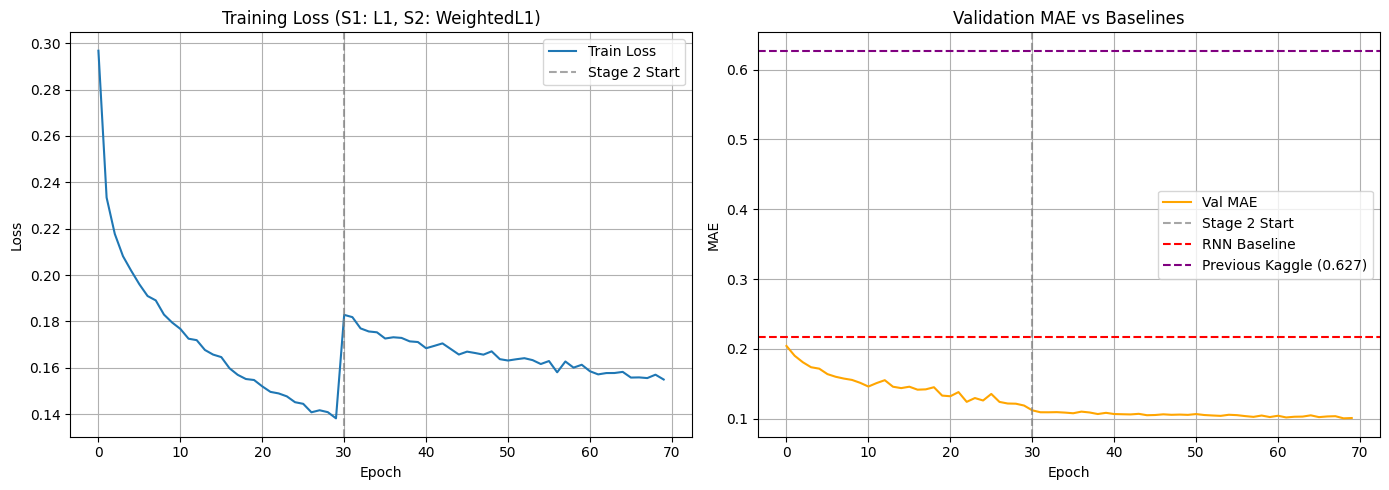


💡 SUBMISSION RECOMMENDATIONS:
1. predictions_chronos_finetuned_opt.csv - Best single model
2. predictions_chronos_weighted.csv - Ensemble (may generalize better)
3. predictions_chronos_ensemble.csv - 50/50 blend

✅ OPTIMIZATION COMPLETE!


In [26]:
# =====================================
# FINAL SUMMARY - OPTIMIZED VERSION
# =====================================

print("="*60)
print("CHRONOS STATE ESTIMATION - OPTIMIZED RESULTS")
print("="*60)

print(f"\n📊 VALIDATION PERFORMANCE:")
print(f"   Zero-Shot ({best_zs_name}):  {zero_shot_mae:.4f}")
print(f"   Fine-Tuned Stage 1:         {best_val_mae:.4f}")
print(f"   Fine-Tuned Stage 2:         {best_val_mae_s2:.4f}")
print(f"   RNN Baseline:               0.217")
print(f"   Previous Kaggle Score:      0.627")

print(f"\n📁 OUTPUT FILES:")
print(f"   1. {output_path_zero_shot.name}")
print(f"   2. {output_path_finetuned.name}")
print(f"   3. {output_path_ensemble.name}")
print(f"   4. {output_path_weighted.name}")

print(f"\n🎯 OPTIMIZATION DETAILS:")
print(f"   ✓ WeightedL1 Loss (threshold=2.0, slope=1.0)")
print(f"   ✓ Two-stage training (S1: L1, S2: WeightedL1)")
print(f"   ✓ Optimized MLP with residual connections")
print(f"   ✓ Multiple zero-shot model comparison")
print(f"   ✓ Ensemble predictions generated")

print(f"\n📐 OUTPUT FORMAT:")
print(f"   All predictions: {EXPECTED_ROWS} rows")
print(f"   Columns: ['predicted_sideslip', 'id']")

# Plot training history with stage markers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Mark stage boundary
s1_epochs = S1_EPOCHS

# Training loss
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].axvline(x=s1_epochs, color='gray', linestyle='--', alpha=0.7, label='Stage 2 Start')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss (S1: L1, S2: WeightedL1)')
axes[0].legend()
axes[0].grid(True)

# Validation MAE
axes[1].plot(history['val_mae'], label='Val MAE', color='orange')
axes[1].axvline(x=s1_epochs, color='gray', linestyle='--', alpha=0.7, label='Stage 2 Start')
axes[1].axhline(y=0.217, color='red', linestyle='--', label='RNN Baseline')
axes[1].axhline(y=0.627, color='purple', linestyle='--', label='Previous Kaggle (0.627)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].set_title('Validation MAE vs Baselines')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("💡 SUBMISSION RECOMMENDATIONS:")
print("="*60)
print("1. predictions_chronos_finetuned_opt.csv - Best single model")
print("2. predictions_chronos_weighted.csv - Ensemble (may generalize better)")
print("3. predictions_chronos_ensemble.csv - 50/50 blend")
print("\n✅ OPTIMIZATION COMPLETE!")